In [1]:
! python -m venv myenv

In [2]:
! python -m ipykernel install --user --name=myenv --display-name "Python (myenv)"

Installed kernelspec myenv in C:\Users\samii\AppData\Roaming\jupyter\kernels\myenv


In [3]:
import sys
print(sys.executable)

c:\Users\samii\OneDrive\Desktop\Mental health socre\myenv\Scripts\python.exe


In [4]:
! pip install pandas numpy scikit-learn matplotlib seaborn xgboost

You should consider upgrading via the 'c:\Users\samii\OneDrive\Desktop\Mental health socre\myenv\Scripts\python.exe -m pip install --upgrade pip' command.


In [5]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("Mental Health Impact.csv")
df.head()


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [7]:
print(f"Columns in the dataset: {df.columns}")
print(f"Shape of the dataset: {df.shape}")

Columns in the dataset: Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')
Shape of the dataset: (5000, 13)


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [9]:
duplicates = df.duplicated().sum()
if duplicates > 0:
    print(f"Number of duplicate rows: {duplicates}")
    if duplicates > 0:
        df = df.drop_duplicates()
    print(f"Duplicate rows found and removed. New shape of the dataset: {df.shape}")
else:   
    print(f"No duplicate rows found. Shape of the dataset remains: {df.shape}")

Number of duplicate rows: 2
Duplicate rows found and removed. New shape of the dataset: (4998, 13)


<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

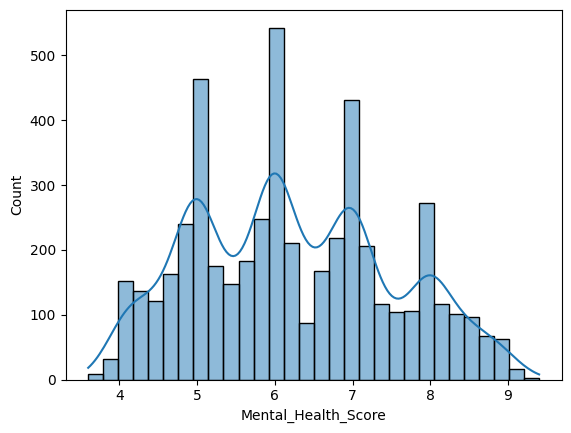

In [10]:
sns.histplot(df['Mental_Health_Score'], bins=30, kde=True)

<Axes: >

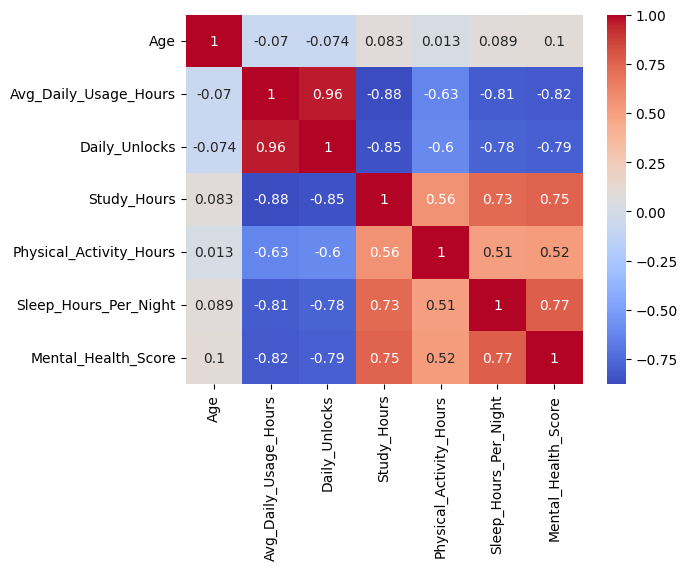

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

## Stress level vs Mental health score

In [12]:
df["Stress_Level"].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

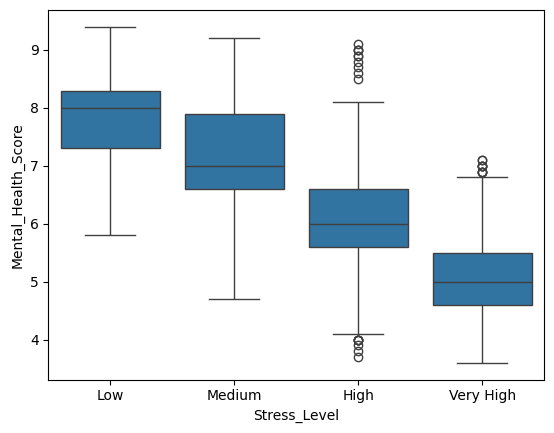

In [13]:
order = ['Low', 'Medium', 'High', 'Very High']
sns.boxplot(x='Stress_Level', y='Mental_Health_Score', data=df, order=order)

## Daliy usage hours vs mental health score

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

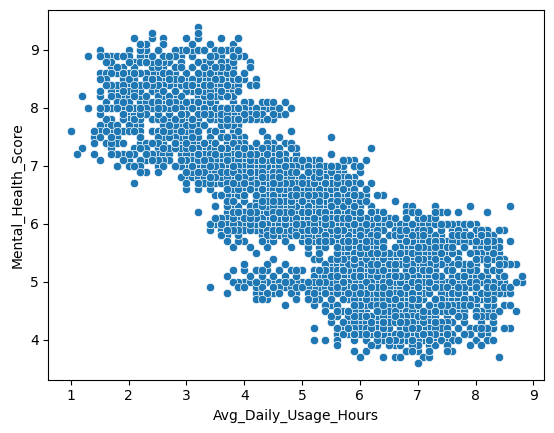

In [14]:
sns.scatterplot(x='Avg_Daily_Usage_Hours', y='Mental_Health_Score', data=df)

## Sleep vs mental healt socer

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

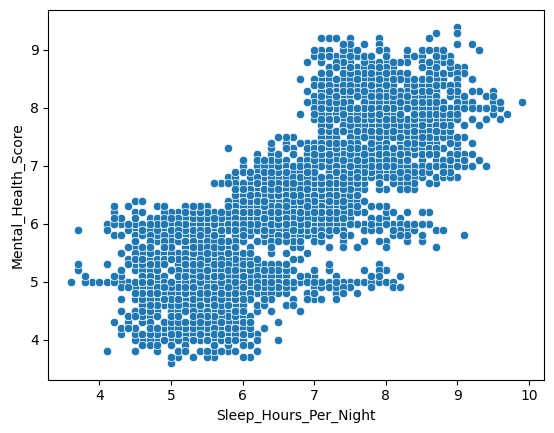

In [15]:
sns.scatterplot(x='Sleep_Hours_Per_Night', y='Mental_Health_Score', data=df)

## study hours vs mental health socre

<Axes: xlabel='Study_Hours', ylabel='Mental_Health_Score'>

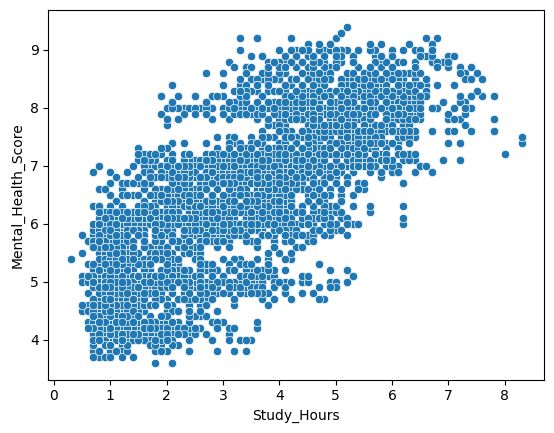

In [16]:
sns.scatterplot(x='Study_Hours', y='Mental_Health_Score', data=df)

## Physical_Activity_Hours vs mental health

<Axes: xlabel='Physical_Activity_Hours', ylabel='Mental_Health_Score'>

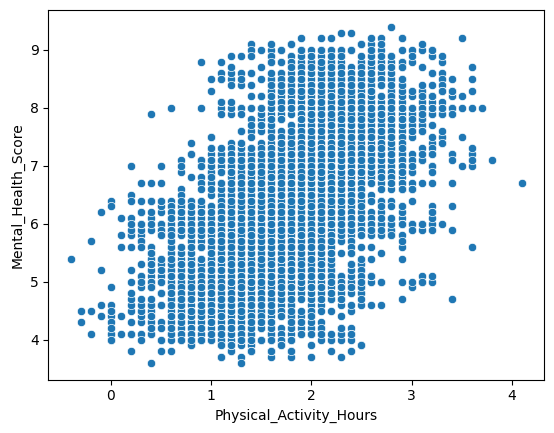

In [17]:
sns.scatterplot(x="Physical_Activity_Hours", y="Mental_Health_Score", data=df)

<Axes: xlabel='Most_Used_Platform', ylabel='count'>

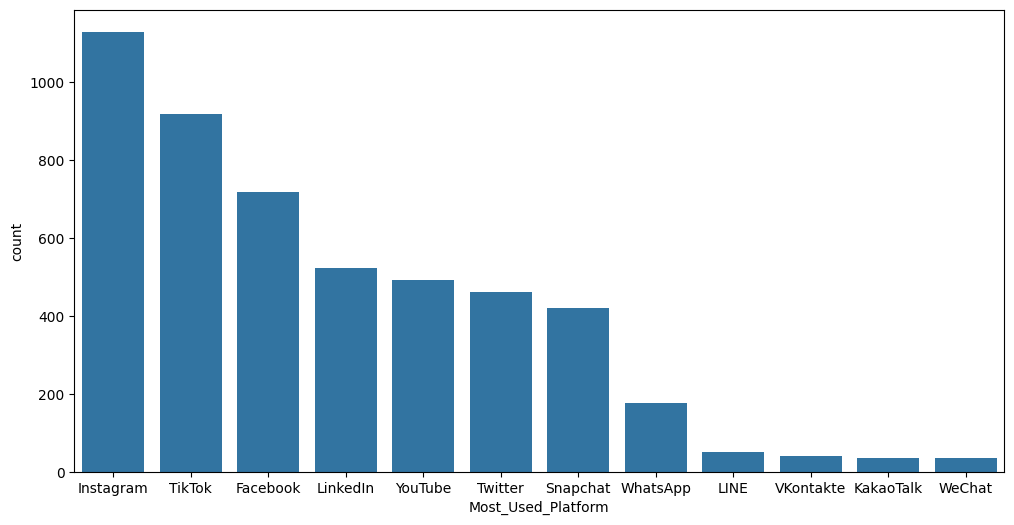

In [18]:
plt.figure(figsize=(12, 6))
sns.countplot(x='Most_Used_Platform', data=df, order=df['Most_Used_Platform'].value_counts().index)

In [19]:
numerical_columns = df.select_dtypes(include="number")
Q1 = numerical_columns.quantile(0.25)
Q3 = numerical_columns.quantile(0.75)
IQR = Q3 - Q1
Lower_Bound = Q1 - 1.5 * IQR
Upper_Bound = Q3 + 1.5 * IQR

outliers = (numerical_columns < Lower_Bound) | (numerical_columns > Upper_Bound)
print(outliers.sum())


Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


## cheacking outliers

<Axes: xlabel='Physical_Activity_Hours'>

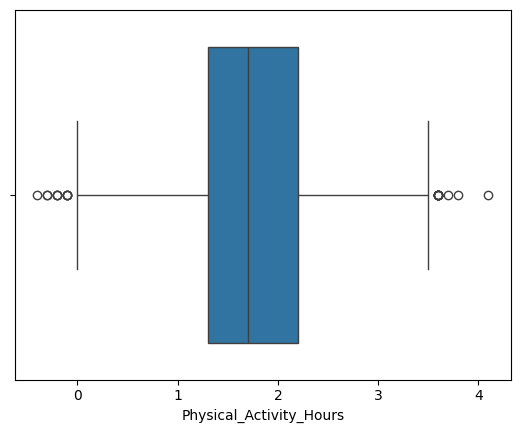

In [20]:
sns.boxplot(data=df, x="Physical_Activity_Hours")

<Axes: xlabel='Study_Hours'>

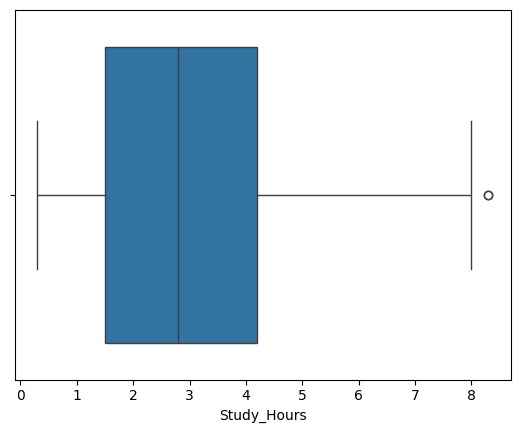

In [21]:
sns.boxplot(data=df, x="Study_Hours")

In [22]:
df["Physical_Activity_Hours"] = df["Physical_Activity_Hours"].clip(lower=0)

In [23]:
df.describe()  

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [24]:
num_col = df.select_dtypes(include="number")

In [25]:
num_col.skew()

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

In [44]:
top_10 =df['Country'].value_counts().index[:10]
top_10

Index(['Other', 'India', 'USA', 'Canada', 'Australia', 'UK', 'Germany',
       'Mexico', 'Turkey', 'France'],
      dtype='object', name='Country')

In [27]:
def group_country(country):
    if country in top_10:
        return country
    else:
        return 'Other'

In [28]:
df['Grouped_Country'] = df["Country"].apply(group_country)

In [29]:
df['Grouped_Country'].value_counts()

Grouped_Country
Other        3231
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

In [30]:
from sklearn.model_selection import train_test_split

skewed_columns = ['Study_Hours']
other_columns = ['Age','Avg_Daily_Usage_Hours','Daily_Unlocks','Physical_Activity_Hours', 'Sleep_Hours_Per_Night']
ordinal_columns = ['Stress_Level']
one_hot_columns = ['Gender','Academic_Level','Most_Used_Platform','Purpose_Of_Use', 'Grouped_Country']

feature_columns = skewed_columns + other_columns + ordinal_columns + one_hot_columns

X = df[feature_columns]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

## Create a piplines

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler , OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

# skew_pipline ko yahan theek kiya hai (tuples ki shakal mein)
skew_pipline = Pipeline(steps=[
    ('log_transformer', FunctionTransformer(np.log1p)), 
    ('scaler', StandardScaler())
])

# Numeric features
plain_numeric_pipeline = Pipeline(steps=[('scaler', StandardScaler())])

# ordinal piplines
ordinal_pipeline = Pipeline(steps=[('ordinal_columns', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))])

# nominal piplines
nominal_pipeline = Pipeline(steps=[('one_hot_encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = column_transformer = ColumnTransformer(transformers=[
    ('skewed_pipline', skew_pipline, skewed_columns), 
    ('Plain_numric', plain_numeric_pipeline, other_columns), 
    ('ordinal', ordinal_pipeline, ordinal_columns),
    ('nominal', nominal_pipeline, one_hot_columns)
])


## Baseline: Liner regression

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('regressor', LinearRegression())
    ])

lr_pipeline.fit(X_train, y_train)

lr_preds = lr_pipeline.predict(X_test)
lr_preds_train = lr_pipeline.predict(X_train)

lr_r2_testing = r2_score(y_test, lr_preds)
lr_r2_training = r2_score(y_train, lr_preds_train)
lr_mae_testing = mean_absolute_error(y_test, lr_preds)

print(f'accuracy of the model on testing data: {lr_r2_testing}')
print(f'accuracy of the model on training data: {lr_r2_training}')
print(f'Mean Absolute Error of the model on testing data: {lr_mae_testing}')


accuracy of the model on testing data: 0.7397944617433021
accuracy of the model on training data: 0.7236771199387539
Mean Absolute Error of the model on testing data: 0.5361775634720182


## Random forest

In [33]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('random forest', RandomForestRegressor(random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_preds = rf_pipeline.predict(X_test)
rf_preds_train = rf_pipeline.predict(X_train)

rf_r2_testing = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_train)
rf_mae_testing = mean_absolute_error(y_test, rf_preds)

print(f'accuracy of the model on testing data: {rf_r2_testing}')
print(f'accuracy of the model on training data: {rf_r2_training}')
print(f'Mean Absolute Error of the model on testing data: {rf_mae_testing}')

accuracy of the model on testing data: 0.8775888638668996
accuracy of the model on training data: 0.9808287942404612
Mean Absolute Error of the model on testing data: 0.34722113333333343


## Hyparameter  tunning 

In [34]:
from sklearn.model_selection import RandomizedSearchCV
parm_grid = {
    'random forest__n_estimators': [100, 200, 300],
    'random forest__max_depth': [5, 10, 15],
    'random forest__min_samples_split': [2, 5, 10],
    'random forest__min_samples_leaf': [1, 2, 4],
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline, 
    param_distributions=parm_grid, 
    n_iter=15, 
    cv=5,
    scoring='r2',  
    random_state=42, 
    n_jobs=-1
)

random_search.fit(X_train, y_train) 

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'random forest__max_depth': [5, 10, ...], 'random forest__min_samples_leaf': [1, 2, ...], 'random forest__min_samples_split': [2, 5, ...], 'random forest__n_estimators': [100, 200, ...]}"
,n_iter,15
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [35]:
random_search.best_params_

{'random forest__n_estimators': 200,
 'random forest__min_samples_split': 5,
 'random forest__min_samples_leaf': 2,
 'random forest__max_depth': 15}

In [36]:
rf_pipeline_best = random_search.best_estimator_
rf_preds_best = rf_pipeline_best.predict(X_test)

print(f'accuracy of the model on testing data: {r2_score(y_test, rf_preds_best)}')
print(f'MAE of the model on testing data: {mean_absolute_error(y_test, rf_preds_best)}')

accuracy of the model on testing data: 0.8650140569761653
MAE of the model on testing data: 0.3689015766630922


##GXboost

In [37]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('xgb', XGBRegressor(random_state=42))
])
    
xgb_pipeline.fit(X_train, y_train)

xgb_preds = xgb_pipeline.predict(X_test)
xgb_preds_train = xgb_pipeline.predict(X_train)

xgb_r2_testing = r2_score(y_test, xgb_preds)
xgb_r2_training = r2_score(y_train, xgb_preds_train)
xgb_mae_testing = mean_absolute_error(y_test, xgb_preds)

print(f'accuracy of the model on testing data: {xgb_r2_testing}')
print(f'accuracy of the model on training data: {xgb_r2_training}')
print(f'Mean Absolute Error of the model on testing data: {xgb_mae_testing}')


accuracy of the model on testing data: 0.877165603954614
accuracy of the model on training data: 0.9751720148923269
Mean Absolute Error of the model on testing data: 0.3519394182523091


## Model evalation 

In [38]:
from sklearn.metrics import mean_squared_error

# caluctate the rmse for the linear regression model
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))

# calculate the rmse for the random forest model
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

# calculate the rmse tuned random forest model
rf_tuned_preds = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_traning = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2 = r2_score(y_test, rf_tuned_preds)

# calculate the rmse for the xgboost model
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))

# carete a dataframe to compare the models
results_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'Tuned Random Forest', 'XGBoost'],
    'r2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2, xgb_r2_testing],
    'traning_r2': [lr_r2_training, rf_r2_training, r2_tuned_traning, xgb_r2_training],
    'mae': [lr_mae_testing, rf_mae_testing, rf_tuned_mae, xgb_mae_testing],
    'rmse': [lr_rmse, rf_rmse, rf_tuned_rmse, xgb_rmse]
})

print(results_df)

                 Model        r2  traning_r2       mae      rmse
0    Linear Regression  0.739794    0.723677  0.536178  0.676032
1        Random Forest  0.877589    0.980829  0.347221  0.463681
2  Tuned Random Forest  0.865014    0.954703  0.368902  0.486915
3              XGBoost  0.877166    0.975172  0.351939  0.464482


## save model 

In [39]:
import joblib
joblib.dump(rf_pipeline, "mental_health_model.pkl")

['mental_health_model.pkl']

## Bulid a fastAPI 

In [45]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score', 'Grouped_Country'],
      dtype='object')

In [46]:
df['Academic_Level'].unique()

array(['Undergraduate', 'Graduate', 'High School'], dtype=object)

In [47]:
df['Most_Used_Platform'].unique()

array(['Facebook', 'LinkedIn', 'Instagram', 'Snapchat', 'Twitter',
       'YouTube', 'TikTok', 'LINE', 'KakaoTalk', 'VKontakte', 'WhatsApp',
       'WeChat'], dtype=object)

In [48]:
df['Purpose_Of_Use'].unique()

array(['Networking', 'Education', 'Entertainment', 'News'], dtype=object)

In [49]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)